# Heart Disease Risk — EDA, modelling and inference
This notebook drives the same package code used by CI (`src/heart/`), so notebook results and pipeline results cannot diverge.

In [1]:
import json
import os

os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
import pandas as pd
from IPython.display import Image, display

from heart import config
from heart.data import load_clean

df = load_clean()
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 1. Data quality

In [2]:
print(df.shape)
print("Missing values:", df.isna().sum()[lambda s: s > 0].to_dict())
print("Positive rate:", round(df[config.TARGET].mean(), 3))
df.describe().T.round(2)

(303, 14)
Missing values: {'ca': 4, 'thal': 2}
Positive rate: 0.459


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 2. EDA figures (generated by `python -m heart.eda`)

{
  "rows": 303,
  "missing_by_column": {
    "ca": 4,
    "thal": 2
  },
  "positive_rate": 0.4587,
  "target_correlation": {
    "thal": 0.526,
    "ca": 0.46,
    "exang": 0.432,
    "oldpeak": 0.425,
    "thalach": -0.417,
    "cp": 0.414,
    "slope": 0.339,
    "sex": 0.277,
    "age": 0.223,
    "restecg": 0.169,
    "trestbps": 0.151,
    "chol": 0.085,
    "fbs": 0.025
  }
}


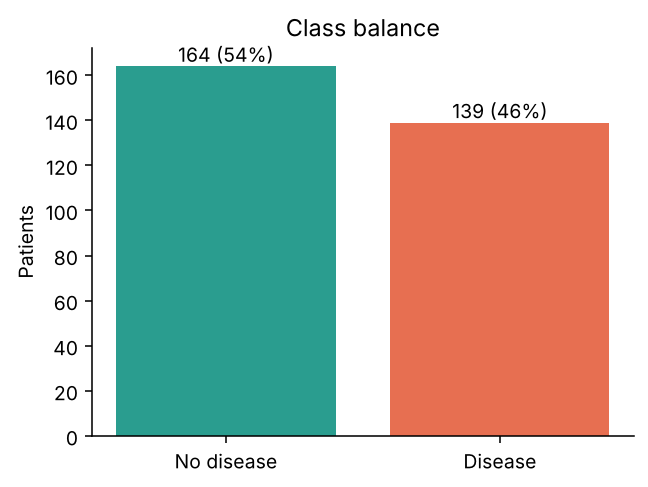

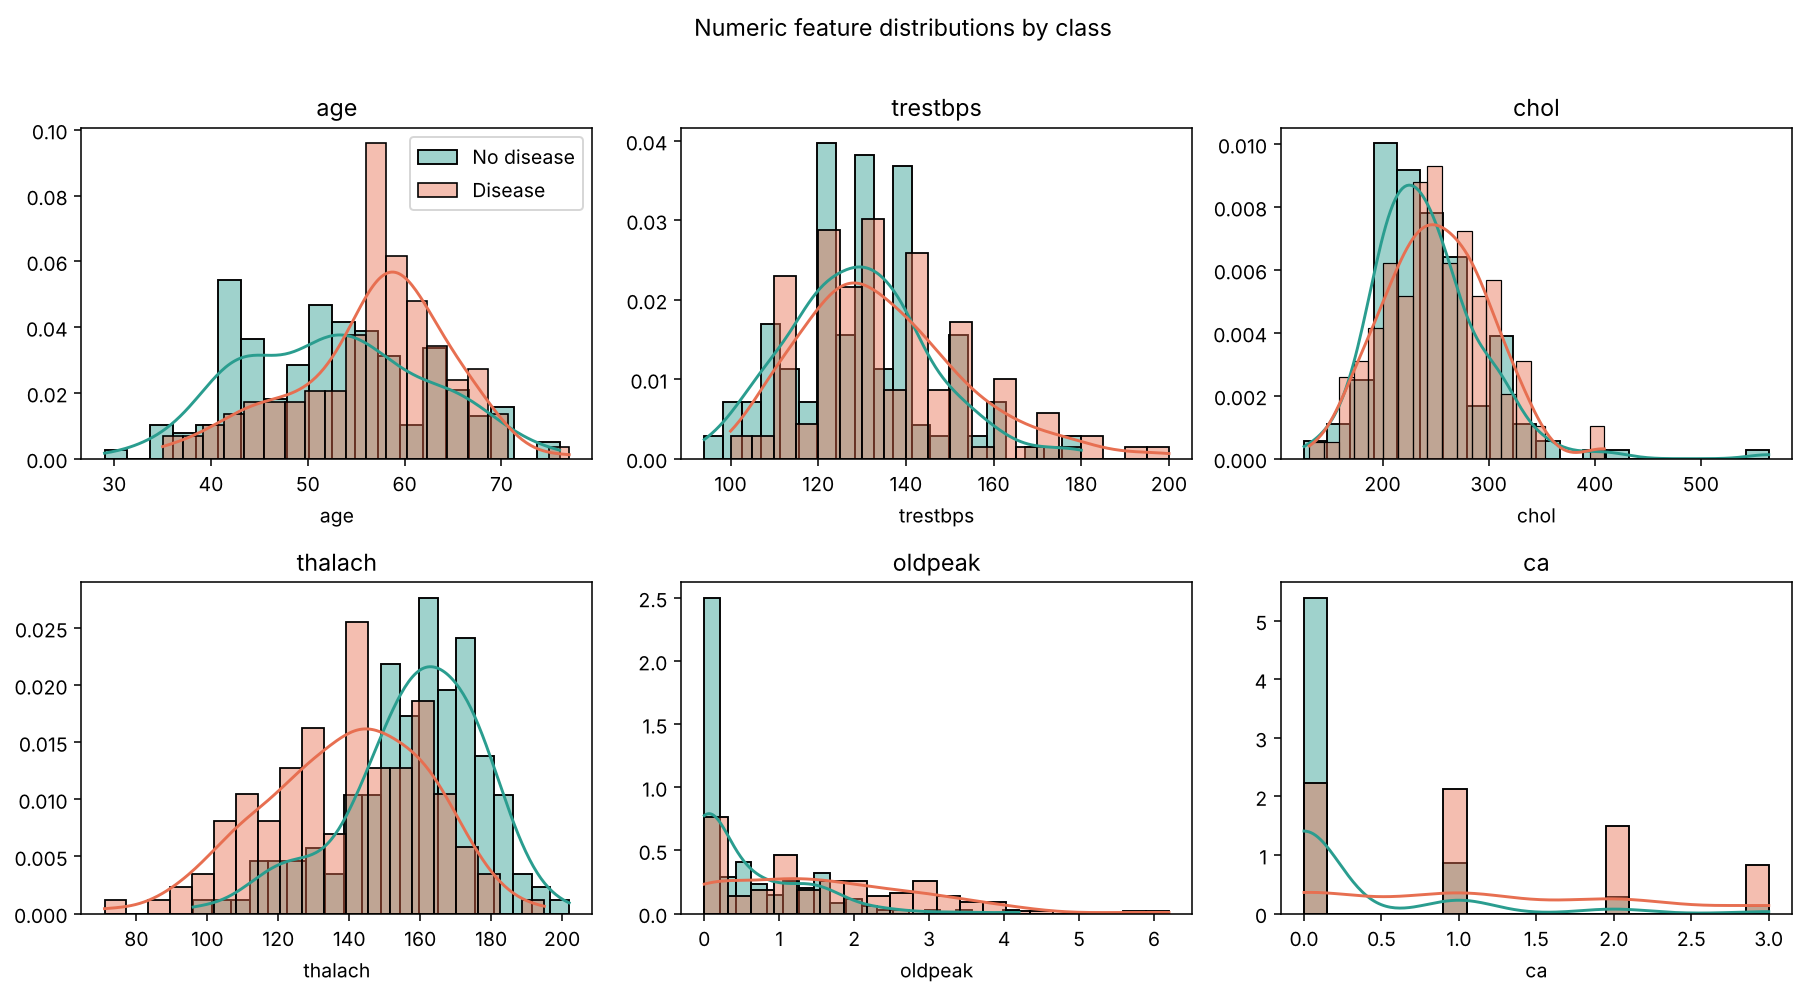

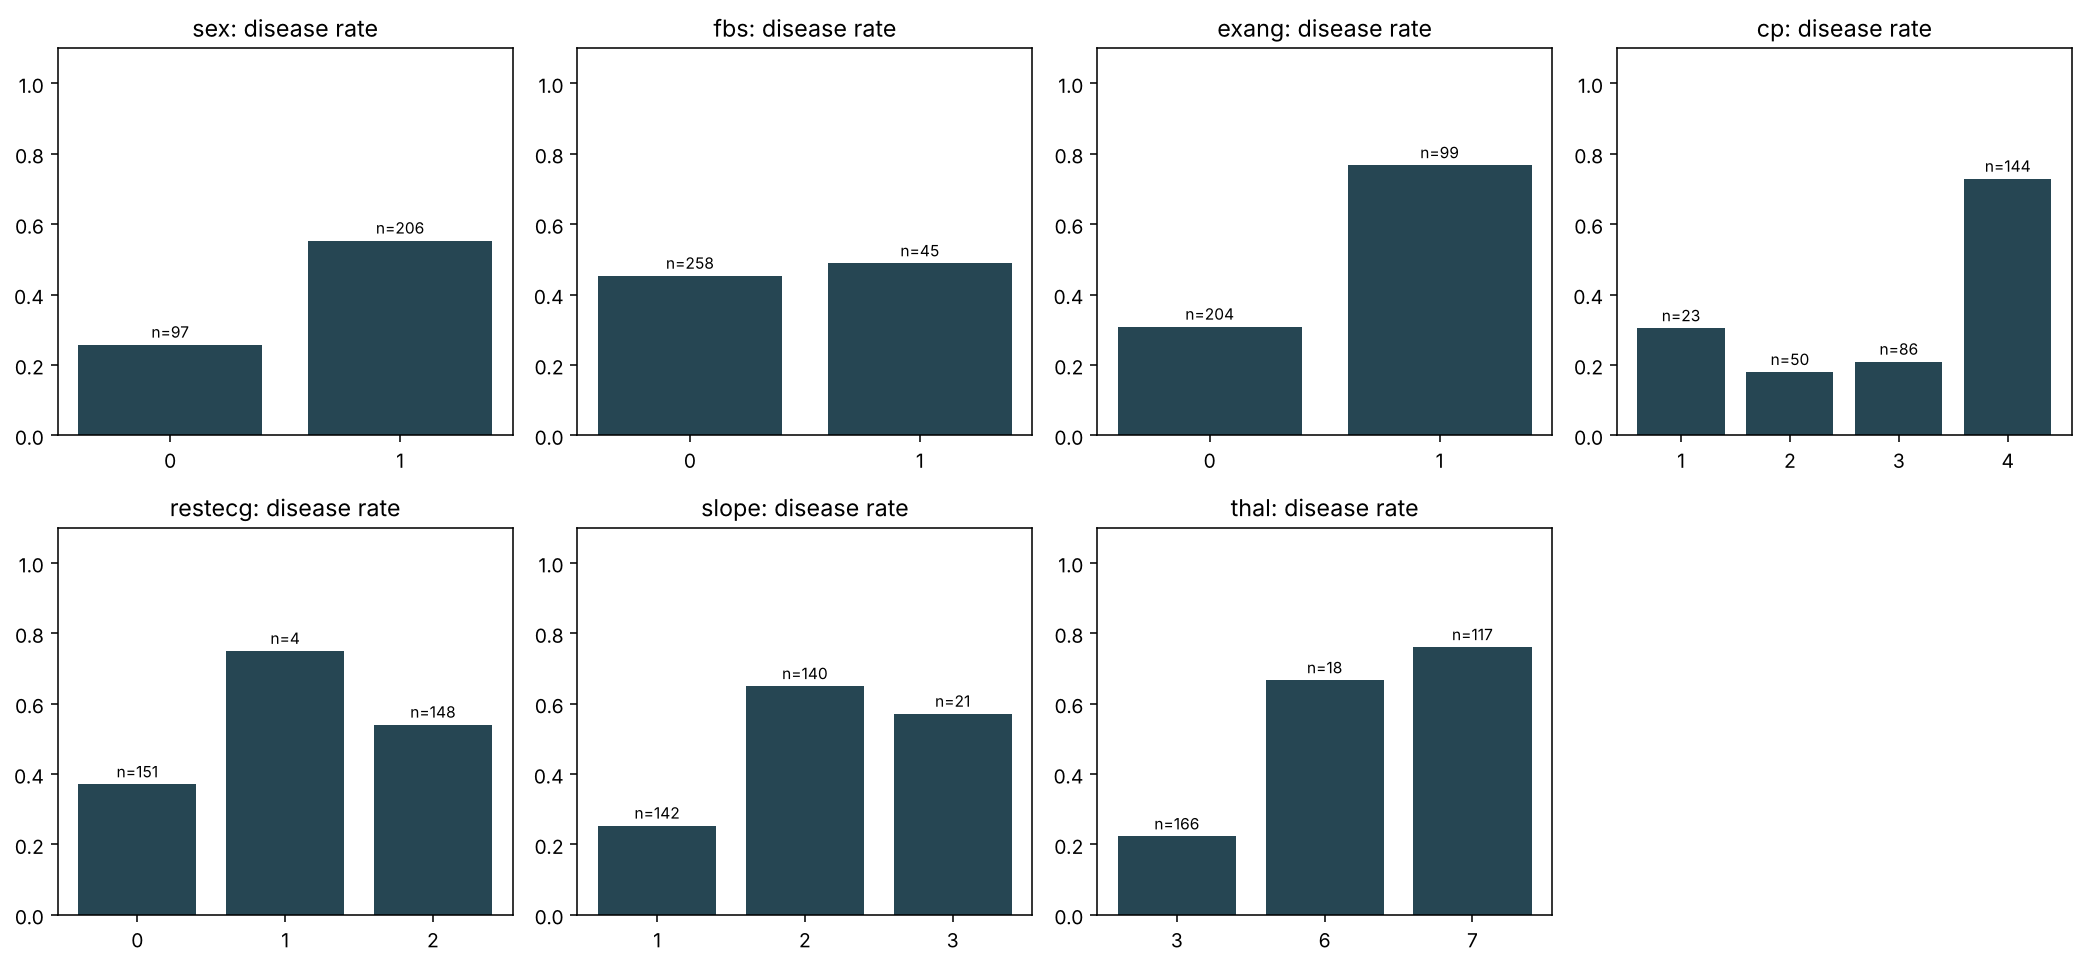

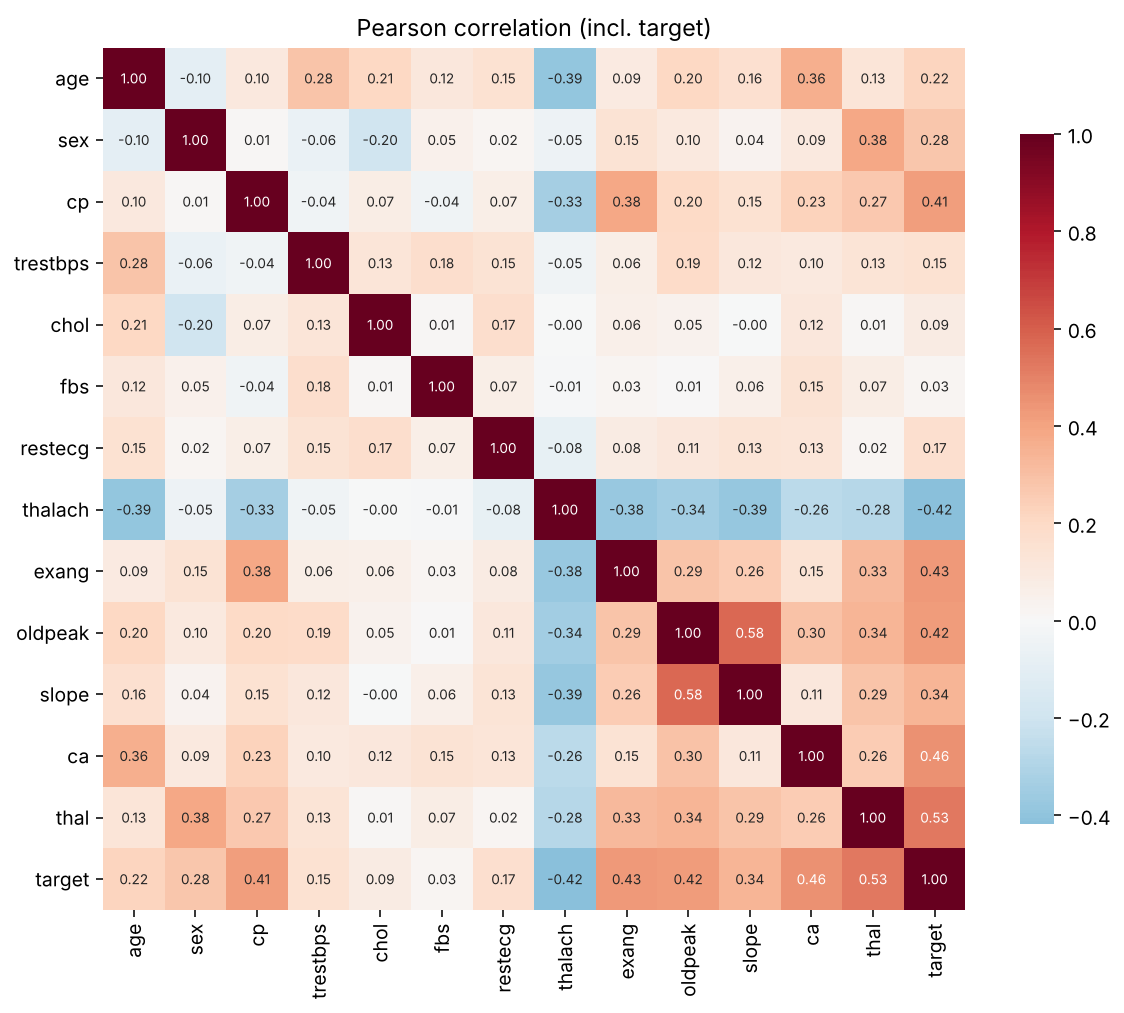

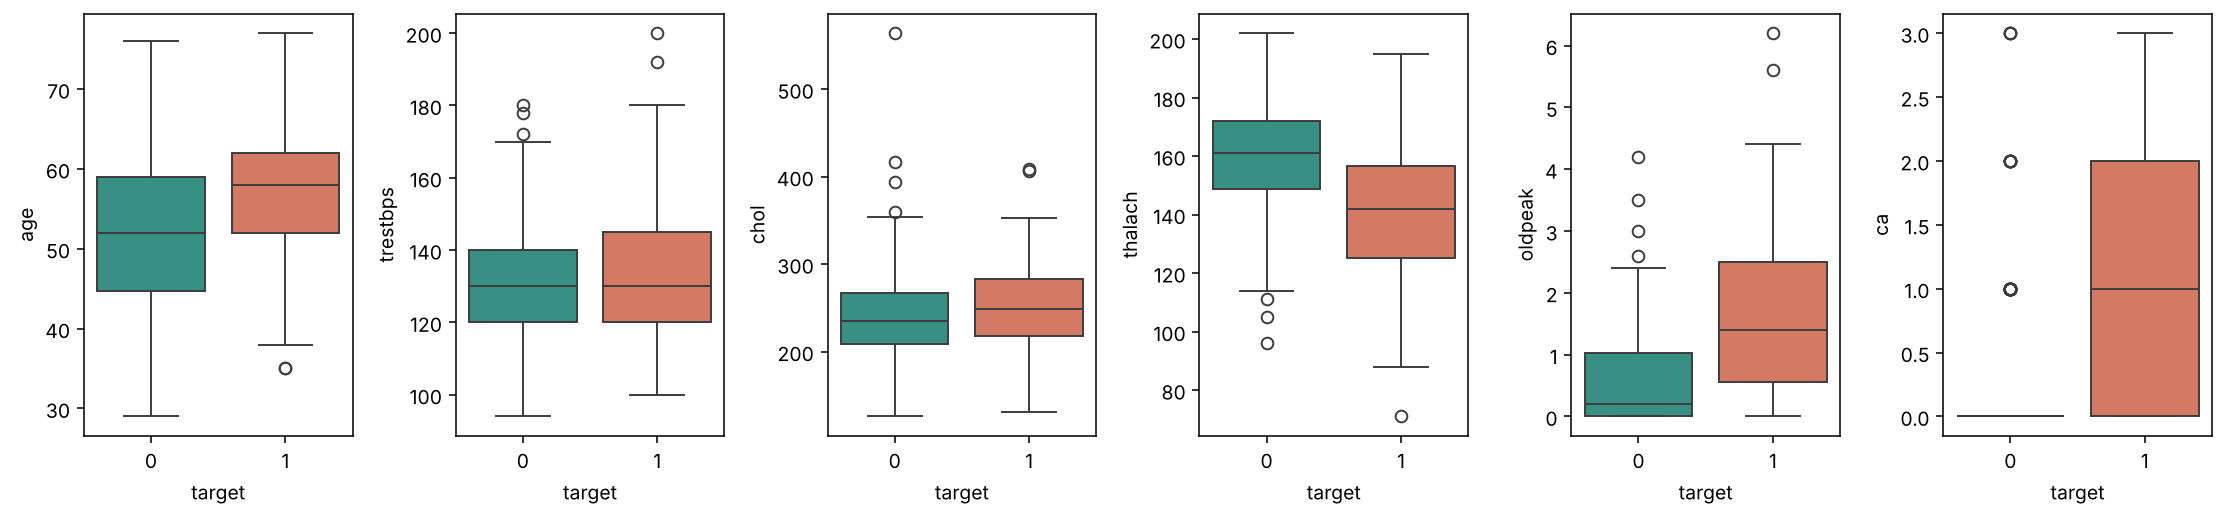

In [3]:
from heart import eda

eda.main()
for f in sorted(config.FIG_DIR.glob("0*.png")):
    display(Image(filename=str(f), width=820))

**Observations.** Classes are near-balanced (54/46), so accuracy is meaningful but ROC-AUC and recall are reported as the primary metrics. `thal`, `ca`, `exang`, `oldpeak`, `cp` and `thalach` carry the strongest signal; `chol` and `fbs` are weak. Only 6 cells are missing (`ca` ×4, `thal` ×2) — imputed inside the pipeline to avoid leakage.

## 3. Model comparison (from `python -m heart.train`, tracked in MLflow)

In [4]:
pd.read_csv(config.ROOT / "reports/model_comparison.csv").drop(columns="run_id").round(4)

,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,logistic_regression,0.8429,0.8782,0.7743,0.8188,0.9068,0.8689,0.8125,0.9286,0.8667,0.9600
1,random_forest,0.8263,0.8409,0.7735,0.8011,0.9006,0.8852,0.8387,0.9286,0.8814,0.9545
2,hist_gradient_boosting,0.8304,0.8460,0.7830,0.8081,0.8886,0.8852,0.8621,0.8929,0.8772,0.9513


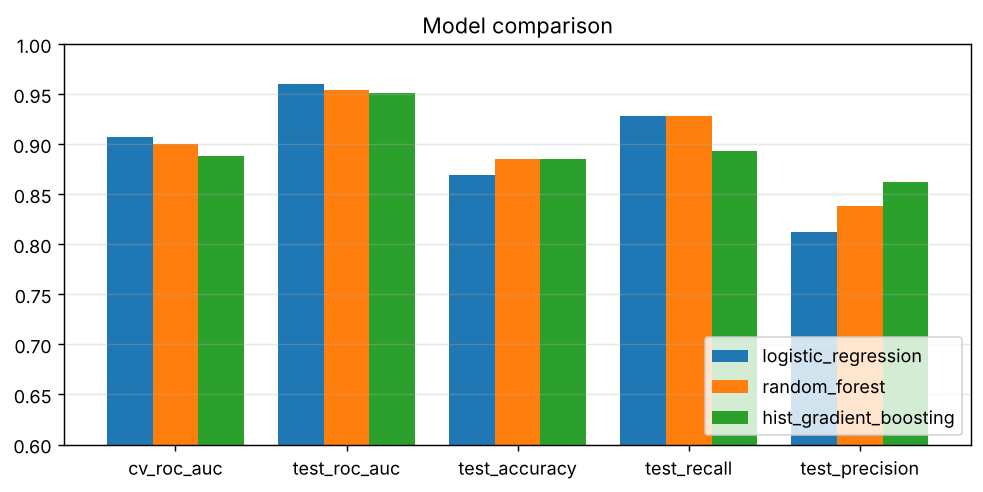

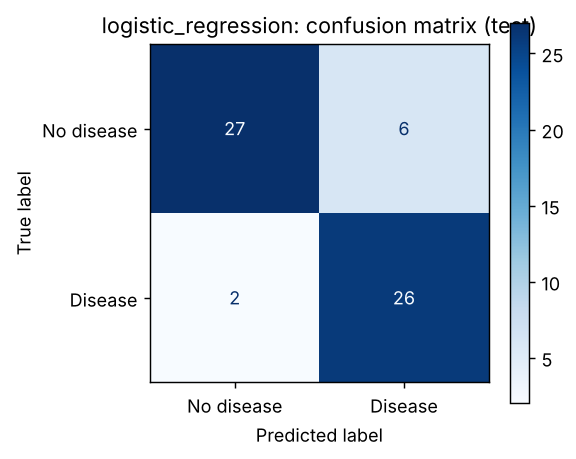

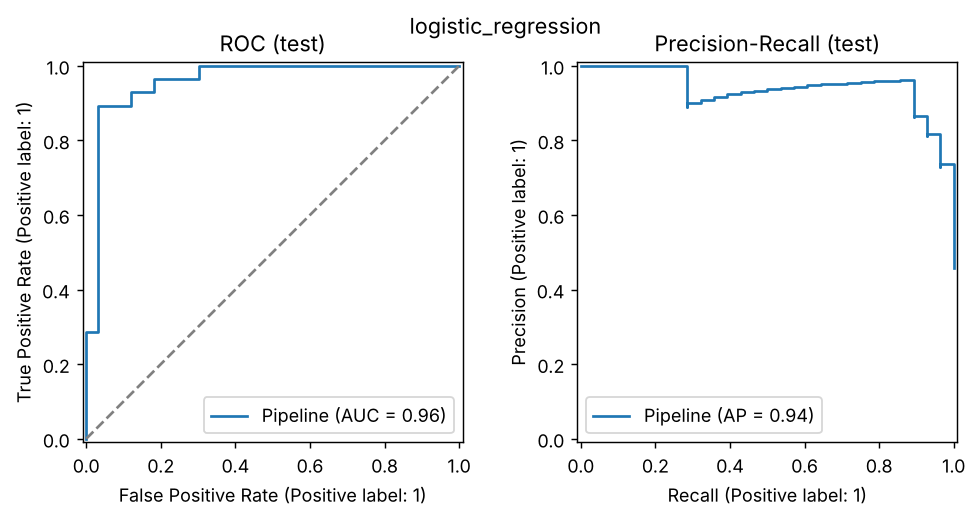

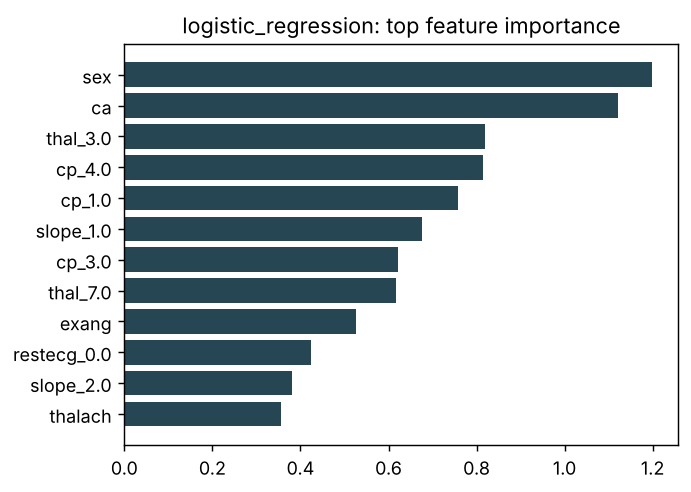

In [5]:
display(Image(filename=str(config.FIG_DIR / "model_comparison.png"), width=820))
for n in ["confusion_matrix", "roc_pr", "feature_importance"]:
    display(Image(filename=str(config.FIG_DIR / f"models/logistic_regression_{n}.png"), width=640))

In [6]:
json.loads((config.META_PATH).read_text())

{'model_name': 'logistic_regression',
 'model_version': '1.0.0',
 'mlflow_run_id': '758cf744a42e499db27b295986240b6b',
 'best_params': {'C': 1.0, 'penalty': 'l2'},
 'metrics': {'cv_accuracy': 0.8429,
  'cv_precision': 0.8782,
  'cv_recall': 0.7743,
  'cv_f1': 0.8188,
  'cv_roc_auc': 0.9068,
  'test_accuracy': 0.8689,
  'test_precision': 0.8125,
  'test_recall': 0.9286,
  'test_f1': 0.8667,
  'test_roc_auc': 0.96},
 'decision_threshold': 0.5,
 'features': ['age',
  'trestbps',
  'chol',
  'thalach',
  'oldpeak',
  'ca',
  'sex',
  'fbs',
  'exang',
  'cp',
  'restecg',
  'slope',
  'thal'],
 'data_sha256': 'e81973d3356c231ed8903aab16f5faa72d9679eb8ef6dc98a602b25df3f5d23d',
 'trained_at': '2026-10-19T19:04:15+00:00',
 'python': '3.13.16',
 'sklearn': '1.9.1'}

## 4. Inference with the packaged pipeline

In [7]:
import joblib

pipe = joblib.load(config.MODEL_PATH)
sample = json.load(open(config.ROOT / "sample_request.json"))
X = pd.DataFrame([sample])[config.FEATURES]
p = pipe.predict_proba(X)[0, 1]
print(f"P(heart disease) = {p:.4f} -> prediction {int(p >= 0.5)}")

P(heart disease) = 0.8986 -> prediction 1
